In [23]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml
import xarray as xr

# Set paths ####################################################################

# Raw data
RAW_DATA_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_10_08.01/data.parquet"
RAW_DATA_5q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/training_data/2026_10_07.01/data.parquet"

# Training results
TRAINING_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_10_08.02"
TRAINING_5q28_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/models/2026_10_15.01/"

# Prediction results
RESULTS_28q0_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_10_08.01/ssp245_shifted.parquet"
RESULTS_5q28_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_16.01/ssp245_shifted.parquet"
RESULTS_5q0_SINGLE_RUN_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/child_mortality/results/2026_10_01.01/ssp245_shifted.parquet"

PLOT_OUTPUT = (
    "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/"
)

# 1. Heatmaps

### Create heatmaps for neonatal mortality

neonatal heatmap: 1,738,010 births, 1,444,084 outside the bin edges (83.1%, mostly zero-exposure)


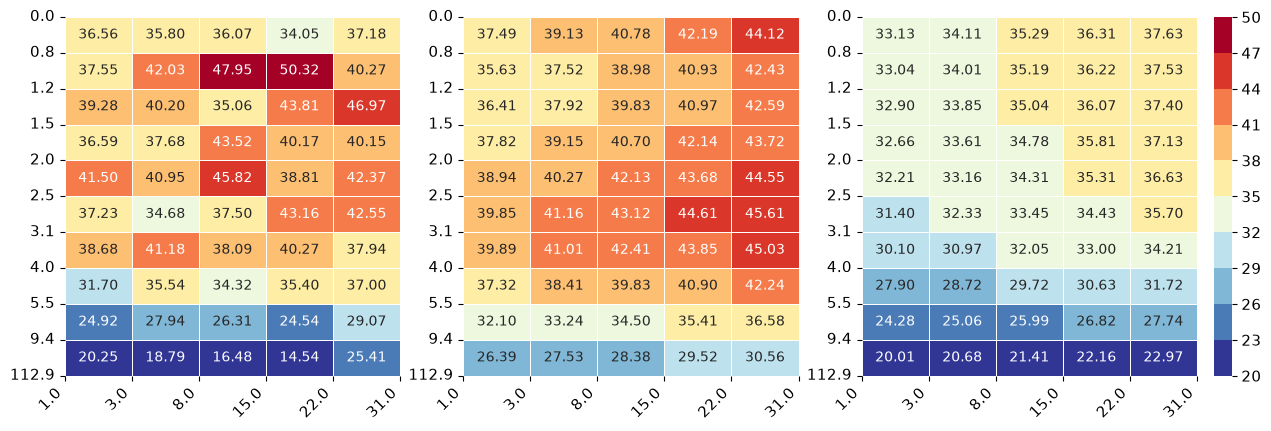

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/neonatal_mortality_heatmaps.png

smallest cell n = 2,047
  Data                     income steps non-monotone 17/45, heat steps non-monotone 18/40
  Predicted, with RE       income steps non-monotone 21/45, heat steps non-monotone 0/40
  Predicted, without RE    income steps non-monotone 0/45, heat steps non-monotone 0/40


In [24]:
# Neonatal mortality heatmaps: data, with RE, without RE ######################
# Bins and colour range follow the pipeline's own neonatal branch in
# training.training_diagnostics.plot_model_heatmaps (rra-climate-health, the
# clone `strun` resolves to): x = [1, 3, 8, 15, 22, 31] with zero-exposure
# births dropped, y = the ten consumption_pd edges, scale fixed at 20-50 deaths
# per 1000, values x1000.
#
# The predictions differ from the pipeline's on purpose. The pipeline plots
# `fits` and `no_re_fits` straight off the fitted frame, so every row carries
# its own sex, income level and rainfall, and moving between cells moves those
# too - the monotone spline constraints do not survive that averaging. Here the
# recipe from notebooks/neonatal/read_predict_models.R (the 11/18 block) is used
# instead: copy the fitted frame, overwrite every covariate that is NOT an axis
# with one representative value, and re-predict. The axes keep their observed
# joint distribution, so the cells are still the real ones; only the nuisance
# terms are flattened.
#
#   sex_id                         mode  (categorical; R pinned one level too)
#   consumption_median_RT          mean  (on the log-transformed scale it is fit on)
#   total_precipitation_prev_0_mo  mean
#   ihme_loc_id                    kept for the with-RE panel, excluded for without
#
# Those predictions are built by a helper that needs rpy2 and the 2.5 GB model
# pickle, so they are cached beside the model rather than recomputed here. The
# build was checked by first reproducing the stored `fits` and `no_re_fits`
# exactly (max absolute difference 0.0) before any covariate was flattened.
import seaborn as sns
import matplotlib.colors as mcolors

NEO_MV = "2026_10_08.02"
NEO_X = "days_over_30C_prev_0_mo"
NEO_Y = "consumption_pd"
NEO_MULT = 1000
NEO_X_BINS = [1, 3, 8, 15, 22, 31]
NEO_Y_BINS = [
    0,
    0.784781,
    1.180789,
    1.541445,
    1.950251,
    2.465952,
    3.103463,
    4.003564,
    5.541124,
    9.413681,
    112.879922,
]
NEO_VMIN, NEO_VMAX = 20, 50
# Sized for a 12.6 x 4.2in slot in a deck, so the png drops in at its native
# aspect and nothing has to be rescaled. Ten income rows in 4.2in is tight, so
# the annotations are smaller than the tick labels.
NEO_FIGSIZE = (12.6, 4.2)
NEO_TICK_SIZE = 11
NEO_ANNOT_SIZE = 10
NEO_PANELS = [
    ("neonatal_mortality", "Data"),
    ("avg_fits", "Predicted, with RE"),
    ("avg_no_re_fits", "Predicted, without RE"),
]
NEO_AVG_FILE = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
NEO_OUT = f"{PLOT_OUTPUT}neonatal_mortality_heatmaps.png"

if not NEO_AVG_FILE.exists():
    msg = (
        f"{NEO_AVG_FILE} not found. Build it with the averaged-covariate helper "
        "(needs rpy2 and scam, so run it in the cluster-dev pixi env, not gbd_env)."
    )
    raise FileNotFoundError(msg)

_neo_raw = pd.read_parquet(
    RAW_DATA_28q0_PATH, columns=[NEO_X, NEO_Y, "neonatal_mortality"]
)
_neo = pd.read_parquet(NEO_AVG_FILE)
if len(_neo) != len(_neo_raw):
    raise ValueError(f"cached predictions {len(_neo):,} vs raw {len(_neo_raw):,} rows")
for _c in (NEO_X, NEO_Y):
    if not np.allclose(_neo[_c].to_numpy(), _neo_raw[_c].to_numpy()):
        raise ValueError(
            f"{_c} differs between the cached predictions and the raw extract"
        )

# the pipeline drops zero-exposure births before binning, so the first bin is
# [1, 3) rather than a zero column
_neo["_x"] = pd.cut(
    _neo.loc[_neo[NEO_X] > 0, NEO_X], bins=NEO_X_BINS, include_lowest=True, right=False
)
_neo["_y"] = pd.cut(_neo[NEO_Y], bins=NEO_Y_BINS, include_lowest=True, right=False)
_neo_kept = _neo[["_x", "_y"]].notna().all(axis=1)
print(
    f"neonatal heatmap: {len(_neo):,} births, {int((~_neo_kept).sum()):,} outside the "
    f"bin edges ({100 * (1 - _neo_kept.mean()):.1f}%, mostly zero-exposure)"
)

_neo_mats = {
    k: _neo.groupby(["_y", "_x"], observed=False)[k].mean().unstack() * NEO_MULT
    for k, _ in NEO_PANELS
}
_neo_n = _neo.groupby(["_y", "_x"], observed=False).size().unstack()

fig, axes = plt.subplots(1, 3, figsize=NEO_FIGSIZE, constrained_layout=True)
_bounds = np.arange(
    NEO_VMIN, NEO_VMAX + (NEO_VMAX - NEO_VMIN) / 10, (NEO_VMAX - NEO_VMIN) / 10
)
_cmap = plt.get_cmap("RdYlBu_r", len(_bounds) - 1)
_norm = mcolors.BoundaryNorm(_bounds, _cmap.N, clip=True)
# Tick formatting follows plot_heat_map_grid in
# notebooks/neonatal/results_plots/2026_3_21_neo_investigation.py: one decimal,
# x rotated 45 and right-aligned, both axes at size 10. Annotations are at 10
# rather than that script's 8. Everything that names the figure is stripped -
# no suptitle, no panel titles, no axis labels, no colourbar label - so the
# panels can be captioned wherever they land. Panel order is still
# Data, with RE, without RE, left to right.
for ax, (k, label) in zip(axes, NEO_PANELS):
    sns.heatmap(
        _neo_mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": NEO_ANNOT_SIZE, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=NEO_VMIN,
        vmax=NEO_VMAX,
        cbar=(k == NEO_PANELS[-1][0]),
        cbar_kws={"ticks": _bounds},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(NEO_X_BINS)))
    ax.set_xticklabels(
        [f"{b:.1f}" for b in NEO_X_BINS],
        rotation=45,
        ha="right",
        fontsize=NEO_TICK_SIZE,
    )
    ax.set_yticks(range(len(NEO_Y_BINS)))
    ax.set_yticklabels(
        [f"{b:.1f}" for b in NEO_Y_BINS], rotation=0, fontsize=NEO_TICK_SIZE
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=NEO_TICK_SIZE)
fig.savefig(NEO_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {NEO_OUT}")

# Monotonicity, reported rather than assumed: income falls down the rows (mpd)
# and heat rises across the columns (mpi). The prediction panels should now obey
# both, because nothing but the axes varies between cells.
print(f"\nsmallest cell n = {int(_neo_n.min().min()):,}")
for k, label in NEO_PANELS:
    m = _neo_mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:24s} income steps non-monotone {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat steps non-monotone {int(np.sum(dx < 0))}/{dx.size}"
    )

### Child mortality

5q28 strata: ['age_6_m', 'age_12_m', 'age_60_m', 'age_24_m', 'age_36_m', 'age_48_m'] + reference age_3_m
model frame: 1,738,010 neonatal rows + 22,263,556 5q28 rows = 24,001,566; person-months 175,796,631
data panel: 23,472,155 of 23,515,189 rows inside the bins (99.8%), 100.0% of person-months, 99.4% of deaths


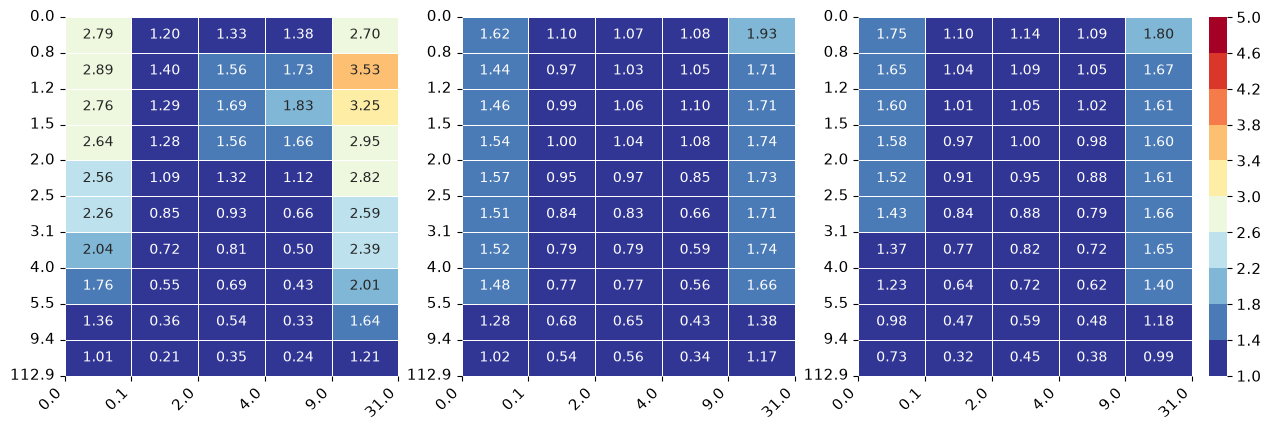

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/child_mortality_heatmaps.png   scale 1-5 deaths per 1000 person-months
panel order: Data, with RE, without RE
  Data                     income steps non-monotone 7/45, heat steps non-monotone 16/40
  Predicted, with RE       income steps non-monotone 10/45, heat steps non-monotone 21/40
  Predicted, without RE    income steps non-monotone 2/45, heat steps non-monotone 20/40

age composition by heat bin (data panel):
             person_month_share_age_1_m  rate_per_1000_pm
_x                                                       
[0.0, 0.1)                       0.0375            2.0925
[0.1, 2.0)                       0.0034            0.7599
[2.0, 4.0)                       0.0084            0.9979
[4.0, 9.0)                       0.0034            0.7760
[9.0, 31.0)                      0.0291            2.5374


In [25]:
# Child mortality heatmaps: 5q0 constructed, data / with RE / without RE ######
# Same three-panel format and the same bins and colour range as the neonatal
# figure above, so the two can be read side by side.
#
# The model side is a COMBINATION of the two fits, not a single model:
#
#   28q0  TRAINING_28q0_PATH  supplies the age_1_m bin, duration 1 month
#   5q28  TRAINING_5q28_PATH  supplies age_3_m .. age_60_m, durations 2,3,6,12,12,12,12
#
# which together span 0-60 months, so the stacked rate is 5q0. The identity
# 5q0 = 1 - (1 - 28q0)(1 - 5q28) is what licenses treating the two as one
# series; it is not applied row by row, because the two models predict
# different rows. In person-time form the numerators and denominators simply
# add, which is the same composition expressed as a rate.
#
# The two measures' covariates are treated as equivalent, which they are: both
# climate variables are days over 30C on a 0-31 scale (the child one is a
# monthly average, not a running total) and both consumption variables run
# 0-75.4. Checked on births present in both extracts: the climate pair
# correlates 0.9960 and the consumption pair 1.0000.
#
# Cells are deaths per 1000 PERSON-MONTHS, following plot_heat_map_person_time
# in notebooks/child_mortality/results_plots/2026_05_08_child_mortality_plots.py:
# sum(value) / sum(duration) per cell. Durations are the interval WIDTHS from
# that script's age_group_durations (line 520), not the bin labels used in its
# earlier block - the labels would put 60 person-months on a 12-month interval.
#
# Non-axis covariates are flattened exactly as in the neonatal cell: sex_id at
# the mode, the other linear terms at their means, random effect kept for the
# with-RE panel and excluded for without. The age dummies are NOT flattened -
# they decide which bin a row sits in and therefore its duration.
import seaborn as sns
import matplotlib.colors as mcolors

CM_DURATIONS = {
    "age_1_m": 1,
    "age_3_m": 2,
    "age_6_m": 3,
    "age_12_m": 6,
    "age_24_m": 12,
    "age_36_m": 12,
    "age_48_m": 12,
    "age_60_m": 12,
}
CM_X, CM_Y = "days_over_30C", "consumption_pd"  # names after the rename below
CM_MULT = 1000
# NOT the neonatal figure's edges. Those were built for a model where every
# row is one month; here the eight age bins are stacked, and this axis is not
# age-neutral - for age_1_m it is exposure during a single month and can reach
# a full 31 days, while for the older bins it is a monthly average over many
# months and regresses toward the middle. Slicing the high end finely therefore
# isolates neonatal rows, which carry ~20x the per-person-month hazard, and the
# top column reads hot for reasons that have nothing to do with temperature:
# with [1, 3, 8, 15, 22, 31] the [22, 31) column drew 38.9% of its person-months
# from age_1_m and hit 16.8 per 1000, against 2.5 for the wide [9, 31) bin here.
# These are the edges and the 1-5 scale used by
# notebooks/child_mortality/results_plots/2026_05_08_child_mortality_plots.py.
CM_X_BINS = [0, 0.1, 2, 4, 9, 31]
CM_Y_BINS = NEO_Y_BINS
CM_FIGSIZE, CM_TICK_SIZE, CM_ANNOT_SIZE = NEO_FIGSIZE, NEO_TICK_SIZE, NEO_ANNOT_SIZE
CM_PANELS = [
    ("value", "Data"),
    ("avg_fits", "Predicted, with RE"),
    ("avg_no_re_fits", "Predicted, without RE"),
]
CM_OUT = f"{PLOT_OUTPUT}child_mortality_heatmaps.png"

# column names differ between the two measures; map both onto one pair of axes
CM_RENAME = {
    "neonatal": {"days_over_30C_prev_0_mo": CM_X, "consumption_pd": CM_Y},
    "child": {"days_over_30C_monthly_cumul": CM_X, "consumption_pd_cumul": CM_Y},
}
CM_AVG_NN = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
CM_AVG_CM = Path(TRAINING_5q28_PATH) / "base_model_avg_covariate_predictions.parquet"
for _p in (CM_AVG_NN, CM_AVG_CM):
    if not _p.exists():
        raise FileNotFoundError(
            f"{_p} not found; build the averaged predictions first."
        )

# ---- Data panel: one extract, all eight bins, real outcomes ----------------
_cm_raw = pd.read_parquet(
    RAW_DATA_5q0_PATH,
    columns=[
        "days_over_30C_monthly_cumul",
        "consumption_pd_cumul",
        "age_group",
        "child_mortality",
    ],
).rename(columns=CM_RENAME["child"])
_cm_raw["dur"] = _cm_raw["age_group"].astype(str).map(CM_DURATIONS)
_cm_raw["value"] = _cm_raw["child_mortality"]
if _cm_raw["dur"].isna().any():
    raise ValueError("age_group values outside CM_DURATIONS")

# ---- Model panels: stack the neonatal bin onto the 5q28 bins ---------------
_nn = pd.read_parquet(CM_AVG_NN).rename(columns=CM_RENAME["neonatal"])
_nn["dur"] = CM_DURATIONS["age_1_m"]
_nn["value"] = np.nan  # the Data panel comes from the extract above

_cm = pd.read_parquet(CM_AVG_CM).rename(columns=CM_RENAME["child"])
_dummies = [c for c in _cm.columns if c in CM_DURATIONS]
_hit = _cm[_dummies].astype(int).to_numpy()
_ref = [a for a in CM_DURATIONS if a not in _dummies and a != "age_1_m"]
if len(_ref) != 1:
    raise ValueError(
        f"expected one reference stratum among the 5q28 dummies, got {_ref}"
    )
_cm["dur"] = np.where(
    _hit.sum(axis=1) == 0,
    CM_DURATIONS[_ref[0]],
    np.array([CM_DURATIONS[d] for d in _dummies])[_hit.argmax(axis=1)],
)
_cm["value"] = np.nan
print(f"5q28 strata: {_dummies} + reference {_ref[0]}")

_cm_mod = pd.concat(
    [
        _nn[[CM_X, CM_Y, "dur", "avg_fits", "avg_no_re_fits"]],
        _cm[[CM_X, CM_Y, "dur", "avg_fits", "avg_no_re_fits"]],
    ],
    ignore_index=True,
)
print(
    f"model frame: {len(_nn):,} neonatal rows + {len(_cm):,} 5q28 rows "
    f"= {len(_cm_mod):,}; person-months {_cm_mod['dur'].sum():,.0f}"
)


# ---- bin, drop zero exposure as the neonatal branch does, aggregate --------
def _cm_cells(frame, col):
    # zero-exposure rows are KEPT; the first bin is [0, 0.1)
    f = frame.copy()
    f["_x"] = pd.cut(f[CM_X], bins=CM_X_BINS, include_lowest=True, right=False)
    f["_y"] = pd.cut(f[CM_Y], bins=CM_Y_BINS, include_lowest=True, right=False)
    f = f[f[["_x", "_y"]].notna().all(axis=1)]
    num = f.groupby(["_y", "_x"], observed=False)[col].sum().unstack()
    den = f.groupby(["_y", "_x"], observed=False)["dur"].sum().unstack()
    return (num / den) * CM_MULT, f


_mats = {}
_mats["value"], _kept_raw = _cm_cells(_cm_raw, "value")
for _k in ("avg_fits", "avg_no_re_fits"):
    _mats[_k], _kept_mod = _cm_cells(_cm_mod, _k)
print(
    f"data panel: {len(_kept_raw):,} of {len(_cm_raw):,} rows inside the bins "
    f"({100 * len(_kept_raw) / len(_cm_raw):.1f}%), "
    f"{100 * _kept_raw.dur.sum() / _cm_raw.dur.sum():.1f}% of person-months, "
    f"{100 * _kept_raw.value.sum() / _cm_raw.value.sum():.1f}% of deaths"
)

CM_VMIN, CM_VMAX = 1.0, 5.0  # as in the reference script

fig, axes = plt.subplots(1, 3, figsize=CM_FIGSIZE, constrained_layout=True)
_bounds = np.linspace(CM_VMIN, CM_VMAX, 11)
_cmap = plt.get_cmap("RdYlBu_r", len(_bounds) - 1)
_norm = mcolors.BoundaryNorm(_bounds, _cmap.N, clip=True)
for ax, (k, label) in zip(axes, CM_PANELS):
    sns.heatmap(
        _mats[k],
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": CM_ANNOT_SIZE, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=CM_VMIN,
        vmax=CM_VMAX,
        cbar=(k == CM_PANELS[-1][0]),
        cbar_kws={"ticks": _bounds},
        linewidths=0.5,
        linecolor="white",
    )
    ax.set_title("")
    ax.set_xticks(range(len(CM_X_BINS)))
    ax.set_xticklabels(
        [f"{b:.1f}" for b in CM_X_BINS], rotation=45, ha="right", fontsize=CM_TICK_SIZE
    )
    ax.set_yticks(range(len(CM_Y_BINS)))
    ax.set_yticklabels(
        [f"{b:.1f}" for b in CM_Y_BINS], rotation=0, fontsize=CM_TICK_SIZE
    )
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=CM_TICK_SIZE)
fig.savefig(CM_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(
    f"Saved {CM_OUT}   scale {CM_VMIN:.0f}-{CM_VMAX:.0f} deaths per 1000 person-months"
)
print("panel order: Data, with RE, without RE")
for k, label in CM_PANELS:
    m = _mats[k].to_numpy()
    dy, dx = np.diff(m, axis=0), np.diff(m, axis=1)
    print(
        f"  {label:24s} income steps non-monotone {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat steps non-monotone {int(np.sum(dx < 0))}/{dx.size}"
    )

# Age composition by heat bin. This matters for reading the figure: the
# neonatal interval carries roughly twenty times the per-person-month hazard of
# the later ones, so any column that is neonatal-heavy reads hot for reasons
# that have nothing to do with temperature. The axis is not neutral here -
# for age_1_m it is exposure during a single month and can reach a full 31
# days, while for the older bins it is a monthly average over many months and
# smooths toward the middle - so the high-exposure columns are unavoidably
# neonatal-heavy.
# plain column sums rather than groupby.apply: `include_groups` only exists
# from pandas 2.2 and the notebook kernel is older
_comp = _kept_raw.copy()
_comp["nn_dur"] = _comp["dur"].where(_comp["age_group"].astype(str) == "age_1_m", 0.0)
_sums = _comp.groupby("_x", observed=False)[["nn_dur", "dur", "value"]].sum()
_comp = pd.DataFrame(
    {
        "person_month_share_age_1_m": _sums["nn_dur"] / _sums["dur"],
        "rate_per_1000_pm": CM_MULT * _sums["value"] / _sums["dur"],
    }
)
print("\nage composition by heat bin (data panel):")
print(_comp.round(4).to_string())

left   23,472,155 child-interval rows, 158,091,382 person-months
middle 23,982,761 rows (1,738,010 neonatal + 22,263,556 5q28), reference stratum age_3_m
right  115,200 lattice rows, 120 x 120 points x 8 intervals


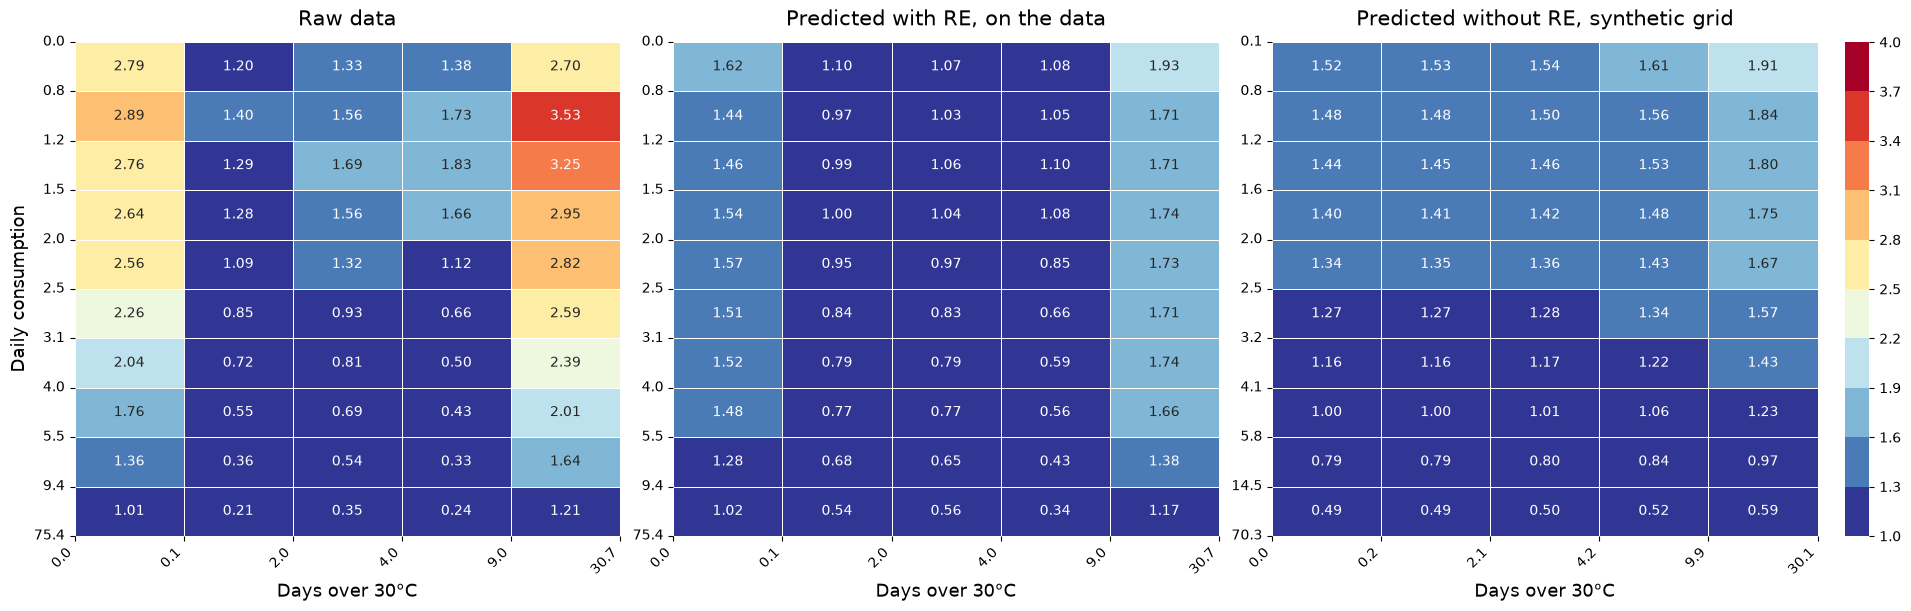


Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/plots/child_mortality_three_panel.png
  Raw data                               range 0.21-3.53  income wrong-way 7/45, heat wrong-way 16/40
  Predicted with RE, on the data         range 0.34-1.93  income wrong-way 10/45, heat wrong-way 21/40
  Predicted without RE, synthetic grid   range 0.49-1.91  income wrong-way 0/45, heat wrong-way 0/40


In [ ]:
# Child mortality, three panels: data | model on the data | model on a grid ###
#
# Left    what actually happened to these children
# Middle  what the model says about THOSE SAME children, random effects included
# Right   what the model says about hypothetical children, everything but the
#         two axes held still, random effects excluded
#
# Reading left to right you move from observation, to the model's account of
# the observations, to the model's shape with the confounding stripped out.
#
# Why there is no max-age reduction here
# --------------------------------------
# Cell 6 reduces each child to their oldest row and divides by `age_month`,
# because that is what the published 2026-05-08 figure does. It cannot be done
# on the right-hand panel - a synthetic grid has no children to reduce and no
# ages to take the maximum of. Mixing the two would put the panels on different
# denominators (they differ by 8.3% on this extract: 145,015,190 person-months
# under max-age against 158,134,417 under interval widths), so all three panels
# here use the SAME convention: every row counts, and each contributes the
# WIDTH of its age interval - 1, 2, 3, 6, 12, 12, 12, 12 months.
#
# How the two models are combined
# -------------------------------
# The neonatal fit supplies the [0, 1) month interval, the 5q28 fit the seven
# from [1, 3) to [48, 60). Together they span 0-60 months, so the stack is 5q0.
# In person-time form the identity 5q0 = 1 - (1 - 28q0)(1 - 5q28) becomes simple
# addition: deaths and months at risk are each summed, then divided.
#
# The formula, the same for every panel
# -------------------------------------
#     rate = 1000 * (sum of deaths or predicted probabilities)
#                 / (sum of age-interval widths)
#
# Left takes real deaths, middle the with-RE predictions on the observed rows,
# right the without-RE predictions on the lattice.
#
# One asymmetry to keep in mind: in the two left panels a cell is weighted by
# how many children actually fall in it; on the grid every lattice point counts
# the same, so a combination almost nobody experiences carries equal weight.
import seaborn as sns
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

P3_DUR = {
    "age_1_m": 1,
    "age_3_m": 2,
    "age_6_m": 3,
    "age_12_m": 6,
    "age_24_m": 12,
    "age_36_m": 12,
    "age_48_m": 12,
    "age_60_m": 12,
}
P3_X, P3_Y = "days_over_30C", "consumption_pd"
P3_X_BINS = [0, 0.1, 2, 4, 9, 31]
P3_Y_BINS = [
    0,
    0.784781,
    1.180789,
    1.541445,
    1.950251,
    2.465952,
    3.103463,
    4.003564,
    5.541124,
    9.413681,
    112.879922,
]
P3_MULT, P3_VMIN, P3_VMAX = 1000, 1.0, 4.0
P3_RECALL = 120
P3_RENAME = {
    "neonatal": {"days_over_30C_prev_0_mo": P3_X, "consumption_pd": P3_Y},
    "child": {"days_over_30C_monthly_cumul": P3_X, "consumption_pd_cumul": P3_Y},
}
P3_OUT = f"{PLOT_OUTPUT}child_mortality_three_panel.png"

_avg_nn = Path(TRAINING_28q0_PATH) / "base_model_avg_covariate_predictions.parquet"
_avg_cm = Path(TRAINING_5q28_PATH) / "base_model_avg_covariate_predictions.parquet"
_grid_f = Path(TRAINING_5q28_PATH) / "synthetic_grid_combined.parquet"
for _p in (_avg_nn, _avg_cm, _grid_f):
    if not _p.exists():
        raise FileNotFoundError(
            f"{_p} not found; build it in the cluster-dev env first."
        )


def _p3_cells(frame, value_col, dur_col):
    f = frame.copy()
    f["_x"] = pd.cut(f[P3_X], bins=P3_X_BINS, include_lowest=True, right=False)
    f["_y"] = pd.cut(f[P3_Y], bins=P3_Y_BINS, include_lowest=True, right=False)
    f = f[f[["_x", "_y"]].notna().all(axis=1)]
    num = f.groupby(["_y", "_x"], observed=False)[value_col].sum().unstack()
    den = f.groupby(["_y", "_x"], observed=False)[dur_col].sum().unstack()
    return (num / den) * P3_MULT, f


# ---- left: the observed outcome, all eight intervals ----------------------
_d = pd.read_parquet(
    RAW_DATA_5q0_PATH,
    columns=[
        "days_over_30C_monthly_cumul",
        "consumption_pd_cumul",
        "age_group",
        "child_mortality",
        "int_birth_year_diff_months",
    ],
).rename(columns=P3_RENAME["child"])
_d = _d[_d["int_birth_year_diff_months"] <= P3_RECALL]
_d["dur"] = _d["age_group"].astype(str).map(P3_DUR)
if _d["dur"].isna().any():
    raise ValueError("age_group values outside P3_DUR")

# ---- middle: with-RE predictions on those same rows, both models stacked ---
_nn = pd.read_parquet(_avg_nn).rename(columns=P3_RENAME["neonatal"])
_nn["dur"] = P3_DUR["age_1_m"]
_cm = pd.read_parquet(_avg_cm).rename(columns=P3_RENAME["child"])
_dummies = [c for c in _cm.columns if c in P3_DUR]
_ref = [a for a in P3_DUR if a not in _dummies and a != "age_1_m"]
if len(_ref) != 1:
    raise ValueError(f"expected one reference stratum, got {_ref}")
_hit = _cm[_dummies].astype(int).to_numpy()
_cm["dur"] = np.where(
    _hit.sum(axis=1) == 0,
    P3_DUR[_ref[0]],
    np.array([P3_DUR[c] for c in _dummies])[_hit.argmax(axis=1)],
)
_mid = pd.concat(
    [_nn[[P3_X, P3_Y, "dur", "avg_fits"]], _cm[[P3_X, P3_Y, "dur", "avg_fits"]]],
    ignore_index=True,
)

# ---- right: the synthetic lattice -----------------------------------------
_gr = pd.read_parquet(_grid_f).rename(columns={"_dur": "dur"})

_mats, _frames = {}, {}
_mats["data"], _frames["data"] = _p3_cells(_d, "child_mortality", "dur")
_mats["me"], _frames["me"] = _p3_cells(_mid, "avg_fits", "dur")
_mats["grid"], _frames["grid"] = _p3_cells(_gr, "pred_fe", "dur")

P3_PANELS = [
    ("data", "Raw data"),
    ("me", "Predicted with RE, on the data"),
    ("grid", "Predicted without RE, synthetic grid"),
]
print(
    f"left   {len(_frames['data']):,} child-interval rows, "
    f"{_frames['data']['dur'].sum():,.0f} person-months"
)
print(
    f"middle {len(_frames['me']):,} rows ({len(_nn):,} neonatal + {len(_cm):,} 5q28), "
    f"reference stratum {_ref[0]}"
)
print(
    f"right  {len(_frames['grid']):,} lattice rows, "
    f"{_frames['grid'][P3_X].nunique()} x {_frames['grid'][P3_Y].nunique()} points "
    f"x {_gr['_stratum'].nunique()} intervals"
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6), constrained_layout=True)
_b = np.linspace(P3_VMIN, P3_VMAX, 11)
_cmap = plt.get_cmap("RdYlBu_r", len(_b) - 1)
_norm = mcolors.BoundaryNorm(_b, _cmap.N, clip=True)
for ax, (k, label) in zip(axes, P3_PANELS):
    m = _mats[k]
    sns.heatmap(
        m,
        ax=ax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 10, "weight": "regular"},
        cmap=_cmap,
        norm=_norm,
        vmin=P3_VMIN,
        vmax=P3_VMAX,
        cbar=(k == P3_PANELS[-1][0]),
        cbar_kws={"ticks": _b},
        linewidths=0.5,
        linecolor="white",
    )
    xl = _frames[k].groupby("_x", observed=False)[P3_X].min().tolist() + [
        float(_frames[k][P3_X].max())
    ]
    yl = _frames[k].groupby("_y", observed=False)[P3_Y].min().tolist() + [
        float(_frames[k][P3_Y].max())
    ]
    ax.set_title(label, fontsize=15, pad=12)
    ax.set_xticks(np.arange(m.shape[1] + 1))
    ax.set_yticks(np.arange(m.shape[0] + 1))
    ax.set_xticklabels([f"{v:.1f}" for v in xl], rotation=45, ha="right", fontsize=10)
    ax.set_yticklabels([f"{v:.1f}" for v in yl], rotation=0, fontsize=10)
    ax.set_xlabel("Days over 30°C", fontsize=13)
    ax.set_ylabel("Daily consumption" if ax is axes[0] else "", fontsize=13)
    if ax.collections and ax.collections[0].colorbar is not None:
        ax.collections[0].colorbar.ax.tick_params(labelsize=10)
        ax.collections[0].colorbar.ax.yaxis.set_major_formatter(
            mticker.FormatStrFormatter("%.1f")
        )
fig.savefig(P3_OUT, dpi=200, bbox_inches="tight")
plt.show()
print(f"\nSaved {P3_OUT}")
for k, label in P3_PANELS:
    v = _mats[k].to_numpy()
    dy, dx = np.diff(v, axis=0), np.diff(v, axis=1)
    print(
        f"  {label:38s} range {np.nanmin(v):.2f}-{np.nanmax(v):.2f}  "
        f"income wrong-way {int(np.sum(dy > 0))}/{dy.size}, "
        f"heat wrong-way {int(np.sum(dx < 0))}/{dx.size}"
    )